# ARI 510 Lab 3 — Multimodal Classification with Pretrained Encoders (Hateful Memes)

All reusable logic lives in `src/`; this notebook only calls it. Splits: `train.jsonl` (train), `dev_seen.jsonl` (dev — all decisions), `test_seen.jsonl` (test — evaluated once at the end).

*Content note: the dataset contains hateful content.*

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
%config InlineBackend.figure_formats = ["jpeg"]  # keeps the notebook small (meme grids)

from src.data import load_split, show_memes, sample_balanced
from src.plots import plot_label_distribution
from src.metrics import compute_metrics
from src import human_eval

SEED = 510
train, dev, test = load_split("train"), load_split("dev"), load_split("test")
splits = {"train": train, "dev": dev, "test": test}
print({k: len(v) for k, v in splits.items()})

{'train': 8500, 'dev': 500, 'test': 1000}


# Part 0 — Look at the data first

## 0.1 Label distribution

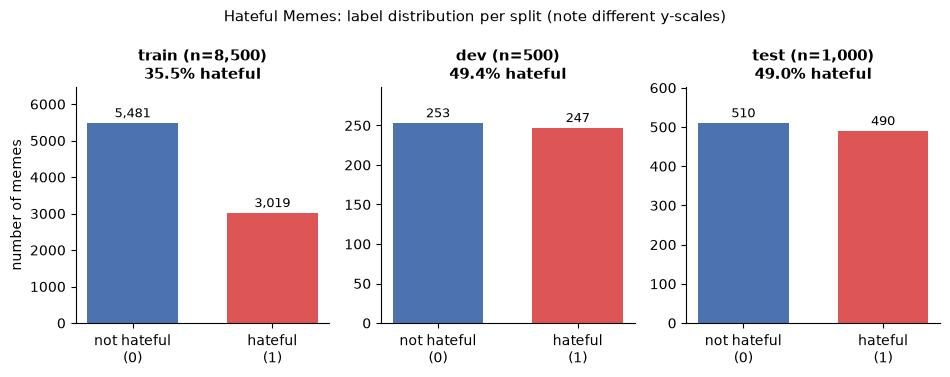

In [2]:
fig = plot_label_distribution(splits, save_path=ROOT / "figures" / "label_distribution.png")
plt.show()

**Note:** train is about 35% hateful, while dev and test are about 49% hateful, so the class balance shifts between training and evaluation.

## 0.2 Look at examples (12 random training memes, 6 hateful / 6 not, fixed seed)

My observations are in `notes/part0_notes.md`.

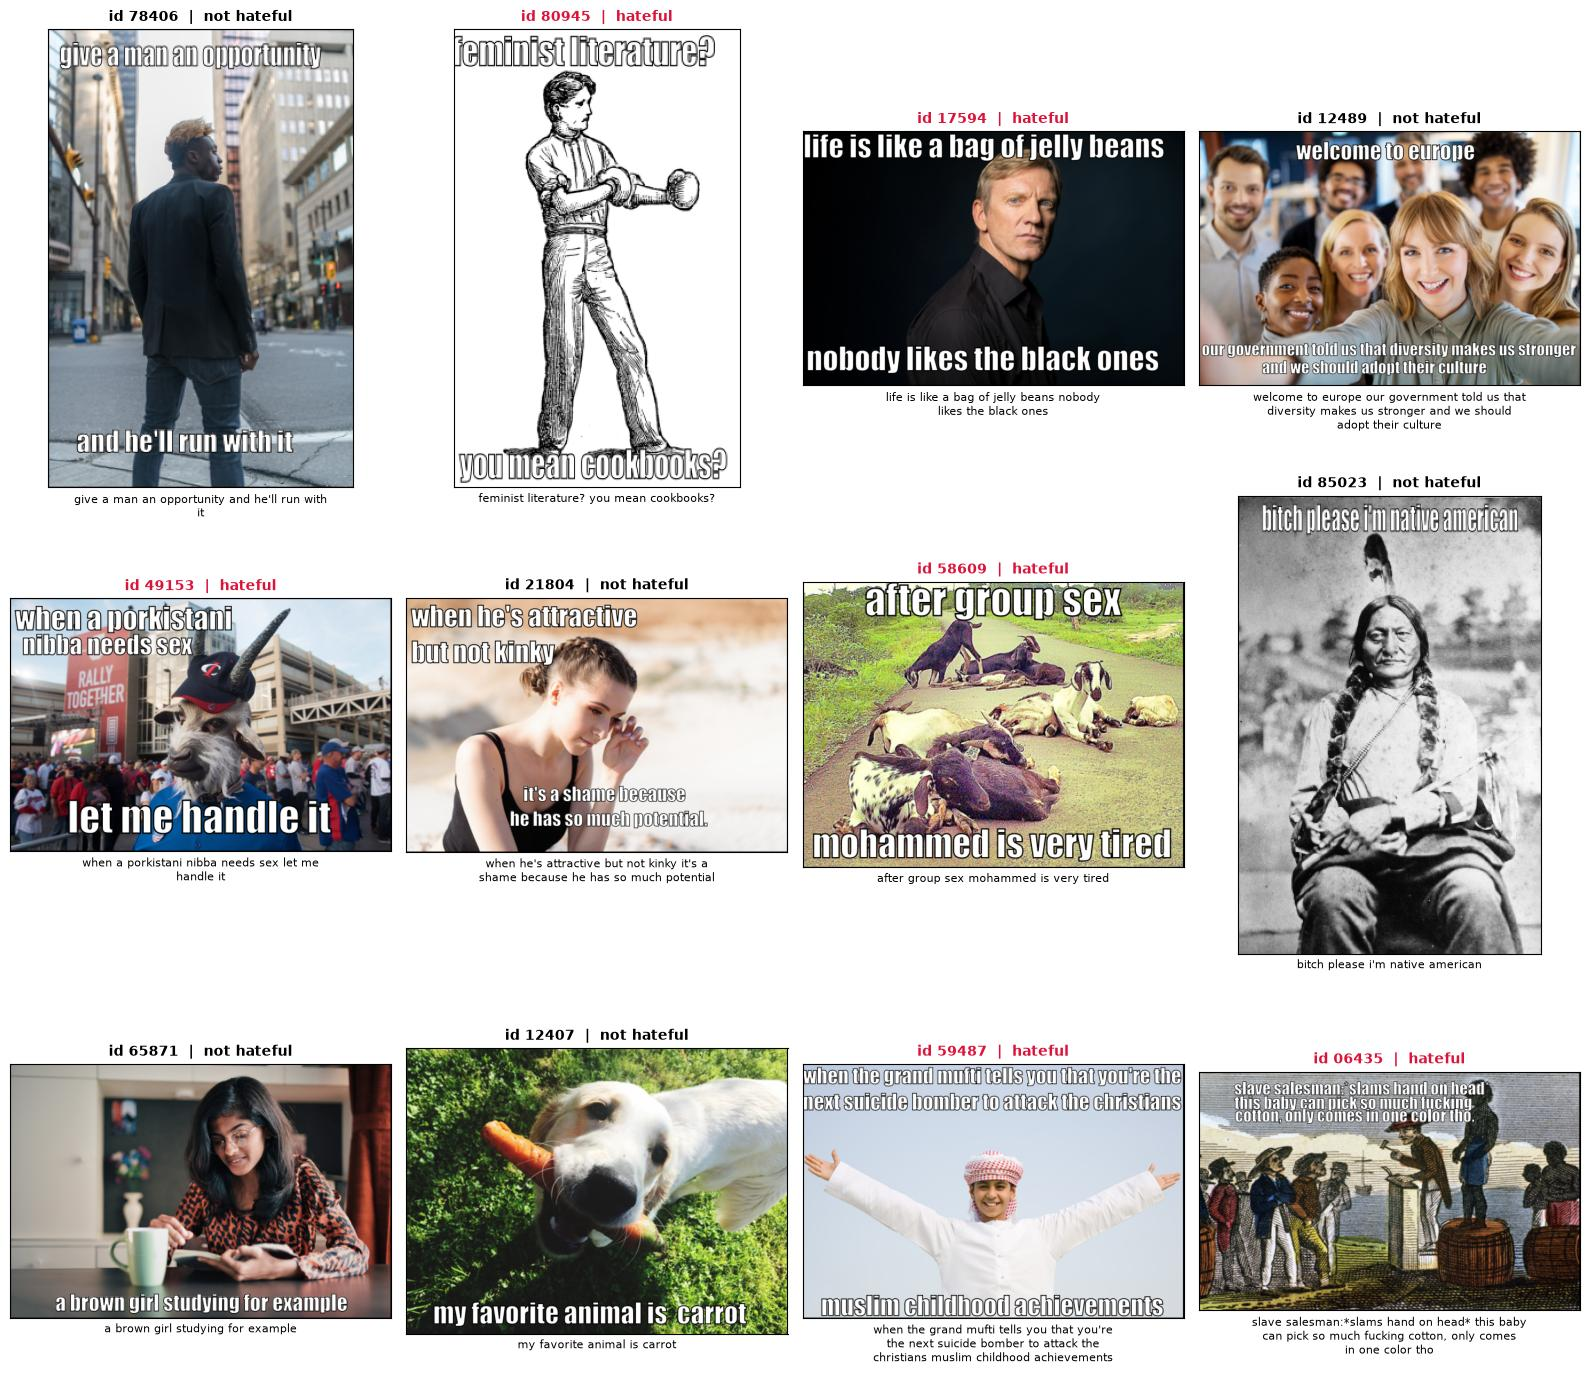

In [3]:
examples = sample_balanced(train, n_per_class=6, seed=SEED)
fig = show_memes(examples, show_label=True, ncols=4)
plt.show()

## 0.3 Be the model — 20 dev memes, labeled blind

1. Run the labeling cell (labels are **not** shown).
2. Fill in `results/human_labels.csv`: `my_guess` (0/1), `needed_both` (y/n), `notes`.
3. Run the scoring cell.

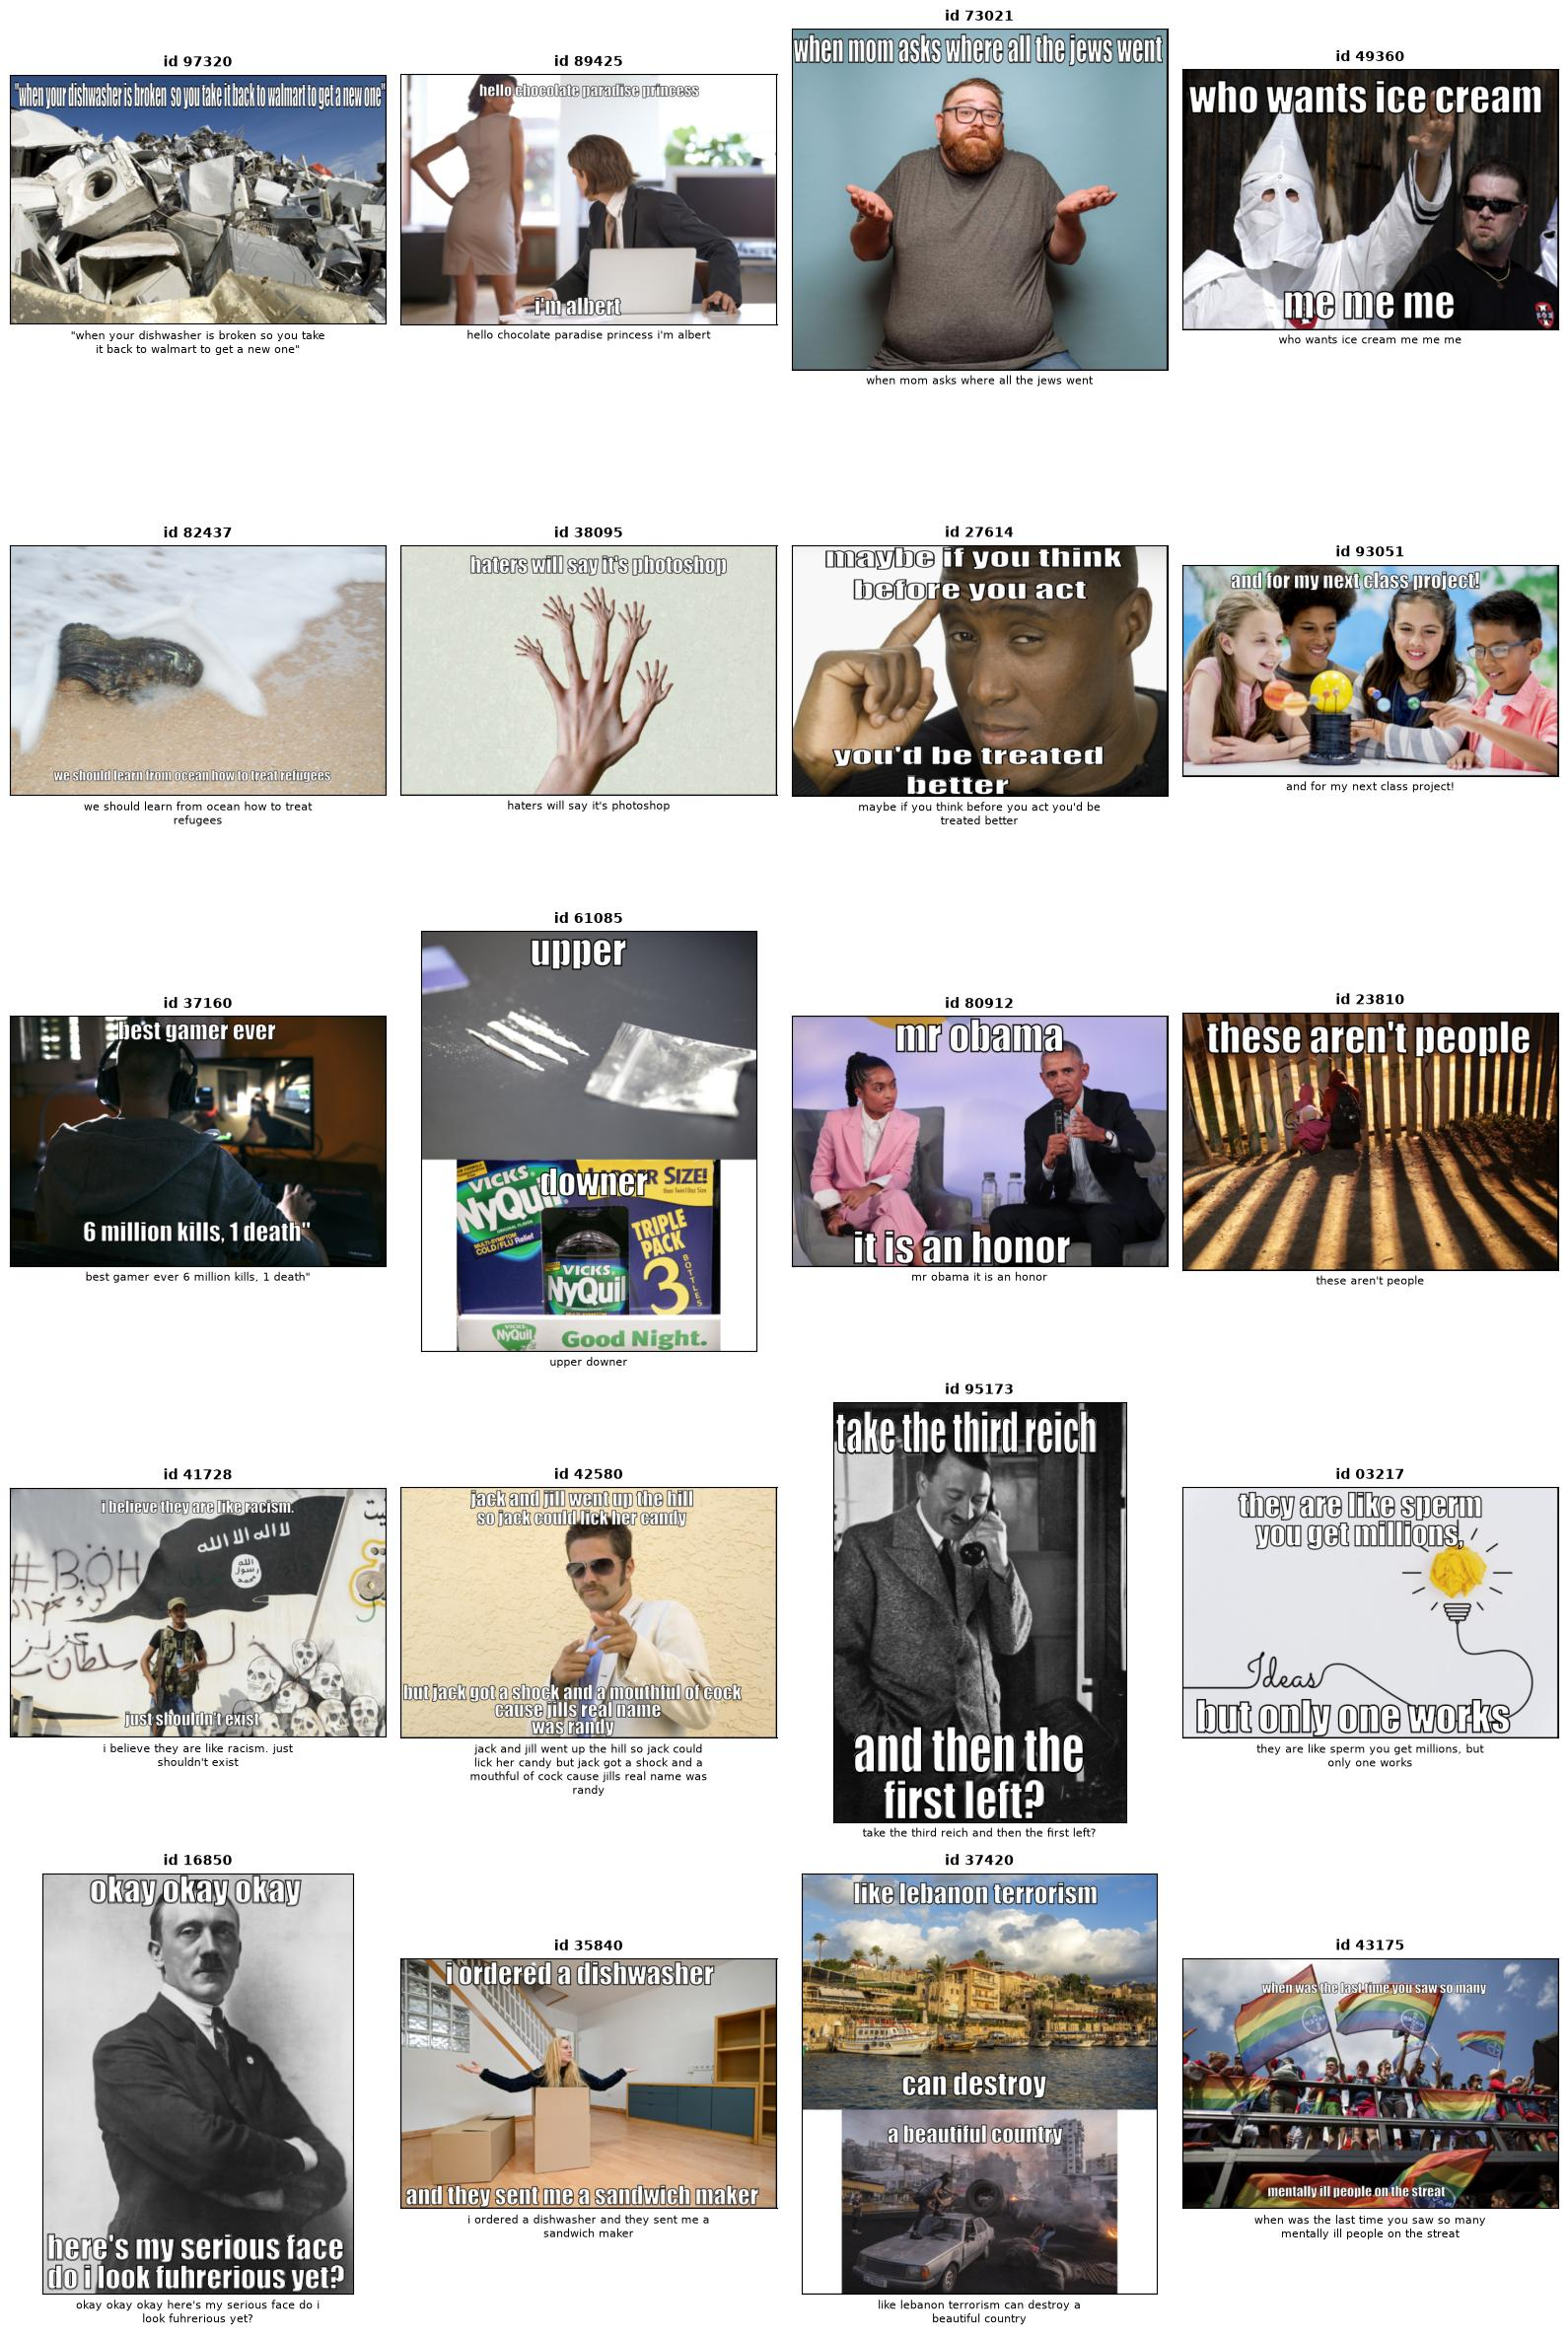

In [4]:
# Labeling cell (blind: no labels anywhere in this output)
blind = human_eval.prepare()
fig = show_memes(blind, show_label=False, ncols=4)
plt.show()

,human (20 dev memes)
accuracy,0.650
precision,0.444
recall,0.667
f1,0.533


,n,correct,accuracy
modality,,,
both,9,4,0.444
image,5,4,0.800
text,6,5,0.833


wrong: 7 / 20


,id,my_guess,label,modality
0,89425,0,1,both
1,73021,1,0,both
2,37160,1,0,both
3,61085,1,0,image
4,23810,0,1,text
5,41728,1,0,both
6,37420,1,0,both


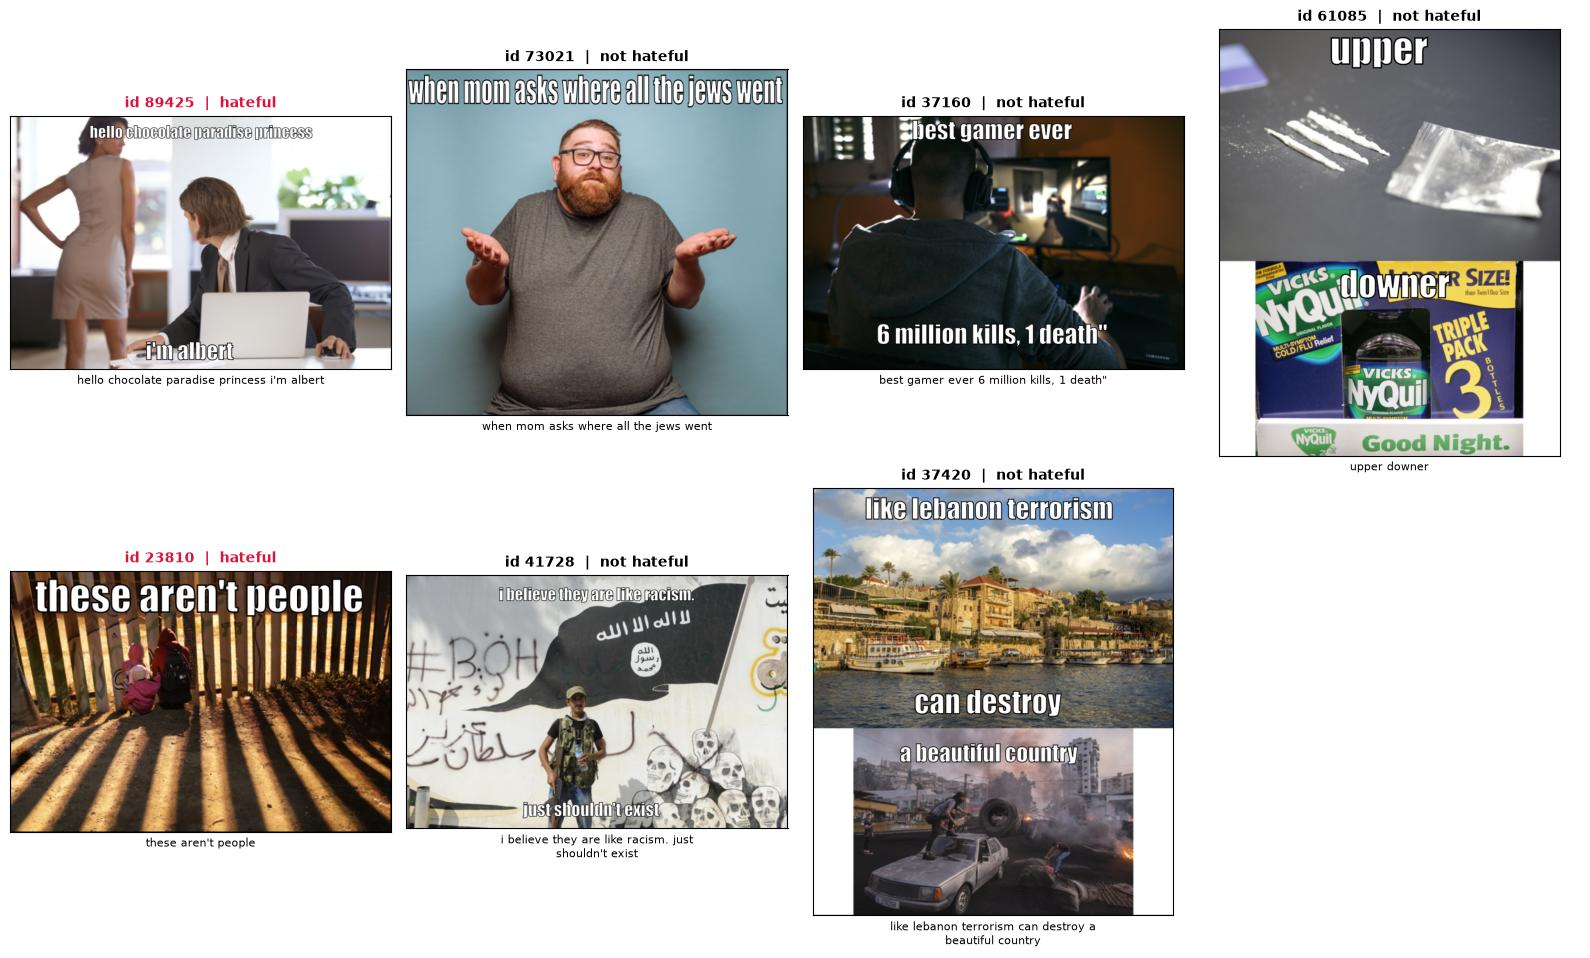

In [5]:
# Scoring cell
result = human_eval.score()
if result is not None:
    human_metrics, wrong, by_modality = result
    display(pd.Series(human_metrics, name="human (20 dev memes)").round(3).to_frame())
    if by_modality is not None:
        display(by_modality.round(3))
    print(f"wrong: {len(wrong)} / 20")
    if len(wrong):
        display(wrong[["id", "my_guess", "label", "modality"]] if "modality" in wrong else wrong[["id", "my_guess", "label"]])
        show_memes(wrong, show_label=True, ncols=4)
        plt.show()

# Embeddings

Computed once with `python -m src.embed --subset all` (frozen encoders, eval mode, `torch.no_grad()`) and cached in `embeddings/`:
- `text_bert`: `bert-base-uncased`, last-layer `[CLS]`, max 128 tokens → 768-d
- `image_resnet`: ResNet-18 (ImageNet weights) with `fc = Identity` → 512-d
- `clip_image`, `clip_text`: open_clip ViT-B/32 (`openai` weights, QuickGELU), raw/unnormalized → 512-d each (510 design change)

In [6]:
from src.features import feature_shapes

feature_shapes()  # shapes only; test features stay locked (load_features("test", ...) raises) until the final evaluation

,split,encoder,shape
0,train,text_bert,"(8500, 768)"
1,train,image_resnet,"(8500, 512)"
2,train,clip_image,"(8500, 512)"
3,train,clip_text,"(8500, 512)"
4,dev,text_bert,"(500, 768)"
5,dev,image_resnet,"(500, 512)"
6,dev,clip_image,"(500, 512)"
7,dev,clip_text,"(500, 512)"
8,test,text_bert,"(1000, 768)"
9,test,image_resnet,"(1000, 512)"


### Why remove ResNet's final layer?

ResNet-18’s final layer maps the 512-number feature vector to scores for 1,000 ImageNet categories (dog, car, mushroom…). Those categories have nothing to do with hateful memes, so the scores would throw away most of the useful information. The 512-number vector before that layer is a general description of what’s in the image (objects, people, textures, layout), so we keep it and train our own classifier on top of it.

# Part 1: Text-only (BERT `[CLS]`, 768-d)

**Primary metric: dev AUROC.** It does not depend on the 0.5 decision threshold, and that matters here because the class balance differs between train (35% hateful) and dev (49%): a model trained on train is pushed toward "not hateful", which shifts thresholded metrics (accuracy, precision, recall, F1) but not the ranking AUROC measures. The thresholded metrics are still reported.

Everything here uses train + dev only; the test split is locked.

In [7]:
from src import experiments as E, features
from src.features import load_features
from src.train import save_model
from src.plots import plot_loss_curves

assert features.TEST_LOCKED, "test must stay locked until the final evaluation"
Xtr, ytr, _ = load_features("train", "text_bert")
Xdev, ydev, _ = load_features("dev", "text_bert")
print(Xtr.shape, Xdev.shape)

torch.Size([8500, 768]) torch.Size([500, 768])


## Sanity checks (text model)

(a) always-"not hateful" baseline on dev, (b) loss of a fresh model on one batch vs ln 2, (c) overfit 20 training examples for 300 epochs. Check (d), the loss curves, is below.

In [8]:
sanity = E.sanity_checks(Xtr, ytr, ydev, save_path=ROOT / "results" / "sanity_text.json")
display(pd.DataFrame({"always not hateful (dev)": sanity["a_dumb_baseline_dev"]}).T.round(3))
b, c = sanity["b_initial_loss"], sanity["c_tiny_overfit"]
print(f"(b) initial loss on one batch: {b['loss']:.4f}   (ln 2 = {b['ln2']:.4f}, diff {b['abs_diff']:.4f})")
print(f"(c) tiny overfit, {c['n_examples']} examples x {c['epochs']} epochs: "
      f"final train loss {c['final_train_loss']:.2e}, train accuracy {c['train_accuracy']:.0%}")

# the checks must still pass
assert b["abs_diff"] < 0.1, "initial loss is far from ln 2"
assert c["final_train_loss"] < 1e-2 and c["train_accuracy"] == 1.0, "tiny-batch overfit failed"
print("sanity checks (b) and (c): PASS")

,accuracy,precision,recall,f1,auroc
always not hateful (dev),0.506,0.0,0.0,0.0,0.5


(b) initial loss on one batch: 0.6585   (ln 2 = 0.6931, diff 0.0347)
(c) tiny overfit, 20 examples x 300 epochs: final train loss 4.87e-05, train accuracy 100%
sanity checks (b) and (c): PASS


## Hyperparameter grid (dev only)

hidden_dim {64, 256, 512} × lr {1e-3, 3e-4, 1e-4, 3e-5} × dropout {0, 0.3} × weight_decay {0, 1e-4} × pos_weight {none, n_neg/n_pos} = 96 configs, seed 0, up to 100 epochs. Each run keeps the epoch with the **highest dev AUROC** (early stopping on the same metric used for model selection; epoch 0 = the untrained model is included). Ranked by dev AUROC. Full grid: `results/grid_text_bert.csv` (computed once, then loaded from that file).

In [9]:
grid = E.run_grid("text_bert", Xtr, ytr, Xdev, ydev, verbose=False)
grid.head(5).round(4)

,hidden_dim,lr,dropout,weight_decay,pos_weight,early_stop_metric,max_epochs,best_epoch,min_dev_loss_epoch,dev_accuracy,dev_precision,dev_recall,dev_f1,dev_auroc,dev_loss,seconds
0,64,0.001,0.0,0.0000,1.8155018091201782,auroc,100,2,0,0.586,0.6205,0.4170,0.4988,0.6348,0.7245,15.1595
1,256,0.001,0.3,0.0001,1.8155018091201782,auroc,100,2,0,0.590,0.6382,0.3927,0.4862,0.6336,0.7218,15.4649
2,64,0.001,0.3,0.0000,1.8155018091201782,auroc,100,2,0,0.592,0.6369,0.4049,0.4950,0.6322,0.7112,14.9865
3,512,0.001,0.0,0.0000,1.8155018091201782,auroc,100,2,0,0.582,0.6033,0.4494,0.5151,0.6317,0.7194,14.4567
4,64,0.001,0.0,0.0001,1.8155018091201782,auroc,100,2,0,0.580,0.6164,0.3968,0.4828,0.6316,0.7269,14.6329


## Chosen config, retrained with seeds 0, 1, 2

In [10]:
best_cfg = E.config_from_row(grid.iloc[0])
print("chosen:", best_cfg)
runs = E.run_seeds(Xtr, ytr, Xdev, ydev, best_cfg)
save_model(runs[0], "text_bert")  # seed-0 model -> results/models/text_bert.pt
pd.DataFrame([{"seed": r.config["seed"], "best_epoch (max dev AUROC)": r.best_epoch,
               "min dev loss epoch": int(np.argmin(r.curves["dev_loss"])), **r.dev_metrics} for r in runs]).round(4)

chosen: {'hidden_dim': 64, 'lr': 0.001, 'dropout': 0.0, 'weight_decay': 0.0, 'pos_weight': 1.8155018091201782}


,seed,best_epoch (max dev AUROC),min dev loss epoch,accuracy,precision,recall,f1,auroc,dev_loss
0,0,2,0,0.586,0.6205,0.4170,0.4988,0.6348,0.7245
1,1,2,0,0.562,0.5909,0.3684,0.4539,0.6210,0.7230
2,2,2,1,0.574,0.5934,0.4372,0.5035,0.6255,0.7118


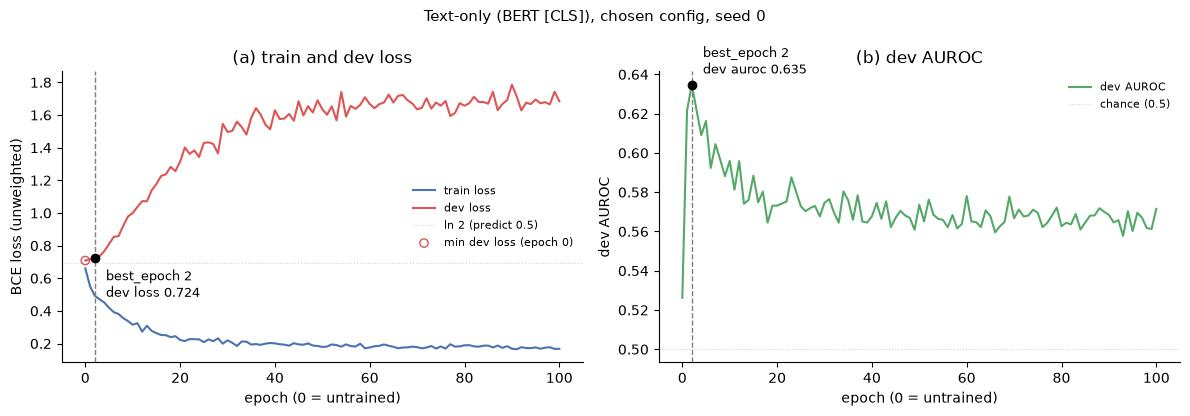

In [11]:
fig = plot_loss_curves(runs[0].curves, runs[0].best_epoch, "Text-only (BERT [CLS]), chosen config, seed 0",
                       save_path=ROOT / "figures" / "curves_text_bert.png")
plt.show()

### Why stop on dev AUROC and not dev loss?

In panel (a), dev loss is lowest at epoch 0 or 1 (for seed 0 it is the *untrained* model) and rises steadily from epoch 1 on, while train loss keeps falling: the network starts overfitting almost immediately. In panel (b), dev AUROC behaves differently: it rises from about 0.53 (untrained) to its peak at epoch 2 (all three seeds), and only then declines as the overfitting takes over. So for the first few epochs dev loss gets worse while dev AUROC gets better. The reason is the overfitting plus the **class-balance shift between train (35% hateful) and dev (49% hateful)**: a model fit to train learns to give low probabilities of "hateful", and as it grows more confident those probabilities are penalised on dev, which raises dev loss, even while its *ranking* of memes (what AUROC measures) is still improving. We therefore stop on **dev AUROC**, the same metric used for model selection.

The slower learning rates did not change the picture: they delay the AUROC peak (on average epoch 19 at lr 3e-5 vs epoch 2 at lr 1e-3) and give only a small dev-loss dip (its minimum is on average at epoch 1.4 at lr 3e-5), but they do not reach a higher dev AUROC (mean over the grid: 0.625 at lr 3e-5 vs 0.629 at lr 1e-3).

Caveat: choosing both the config and the epoch on the same 500 dev memes makes the dev numbers somewhat optimistic; the one-time test evaluation at the end gives the unbiased estimate.

## Dev results so far

In [12]:
E.record_dev_result("always_not_hateful", [sanity["a_dumb_baseline_dev"]], notes="constant prediction 0")
E.record_dev_result("text_bert", [r.dev_metrics for r in runs], notes=f"{best_cfg}; seeds 0,1,2")
E.dev_table()

,accuracy,precision,recall,f1,auroc,runs
model,,,,,,
always_not_hateful,0.506 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,1
text_bert,0.574 ± 0.012,0.602 ± 0.016,0.408 ± 0.035,0.485 ± 0.027,0.627 ± 0.007,3
